# 03 — K-Nearest Neighbors Classification

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Unified leak-free preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Mathematical Euclidean Distance: Raw vs. Standardized


In [3]:
# Calculation Script
diff_age = 40 - 30
diff_inc = 42000 - 40000
diff_score = 700 - 650

# (i) Raw Distance
d_raw = np.sqrt(diff_age**2 + diff_inc**2 + diff_score**2)
share_income = (diff_inc**2) / (d_raw**2) * 100

# (ii) Standardized Distance
std_age = 10.0
std_inc = 15000.0
std_score = 70.0

z_age = diff_age / std_age
z_inc = diff_inc / std_inc
z_score = diff_score / std_score

d_std = np.sqrt(z_age**2 + z_inc**2 + z_score**2)

print('=== Euclidean Distance Proof ===')
print(f'Raw Euclidean Distance:           {d_raw:.2f}')
print(f'Income Share of Raw Distance Sq:  {share_income:.2f}%')
print(f'Standardized Euclidean Distance:  {d_std:.4f}')
print(f'Standardized Component Shares: Age={z_age**2/d_std**2*100:.1f}%, Score={z_score**2/d_std**2*100:.1f}%, Income={z_inc**2/d_std**2*100:.1f}%')


=== Euclidean Distance Proof ===
Raw Euclidean Distance:           2000.65
Income Share of Raw Distance Sq:  99.94%
Standardized Euclidean Distance:  1.2361
Standardized Component Shares: Age=65.4%, Score=33.4%, Income=1.2%


## 4. Hyperparameter Tuning: Tuning $k$ and Bias-Variance Tradeoff


In [4]:
# Transform training and test data once for speed
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

k_values = [1, 3, 5, 9, 15, 21, 31, 41, 51, 65, 75]
train_acc_list = []
test_acc_list = []
cv_acc_list = []
cv_auc_list = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights='uniform')
    knn.fit(X_train_trans, y_train)
    
    # Train & Test Accuracy
    train_acc_list.append(accuracy_score(y_train, knn.predict(X_train_trans)))
    test_acc_list.append(accuracy_score(y_test, knn.predict(X_test_trans)))
    
    # 5-Fold CV Accuracy & AUC
    cv_scores = cross_val_score(knn, X_train_trans, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_auc_scores = cross_val_score(knn, X_train_trans, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_acc_list.append(cv_scores.mean())
    cv_auc_list.append(cv_auc_scores.mean())

# Compile tuning dataframe
df_k_tuning = pd.DataFrame({
    'k': k_values,
    'Train_Accuracy': train_acc_list,
    'Test_Accuracy': test_acc_list,
    'CV_Accuracy': cv_acc_list,
    'CV_ROC_AUC': cv_auc_list
})
df_k_tuning.to_csv('../../outputs/tables/knn_k_tuning_results.csv', index=False)
display(df_k_tuning)

,k,Train_Accuracy,Test_Accuracy,CV_Accuracy,CV_ROC_AUC
0,1,1.000000,0.7815,0.786875,0.636398
1,3,0.897250,0.8155,0.829375,0.742876
2,5,0.877500,0.8295,0.839375,0.779033
3,9,0.865250,0.8335,0.840875,0.816313
4,15,0.856375,0.8355,0.841000,0.834390
5,21,0.850500,0.8370,0.840000,0.846631
6,31,0.845500,0.8400,0.837125,0.851567
7,41,0.842375,0.8350,0.836375,0.855805
8,51,0.842625,0.8350,0.836750,0.858139
9,65,0.839125,0.8320,0.834750,0.859438


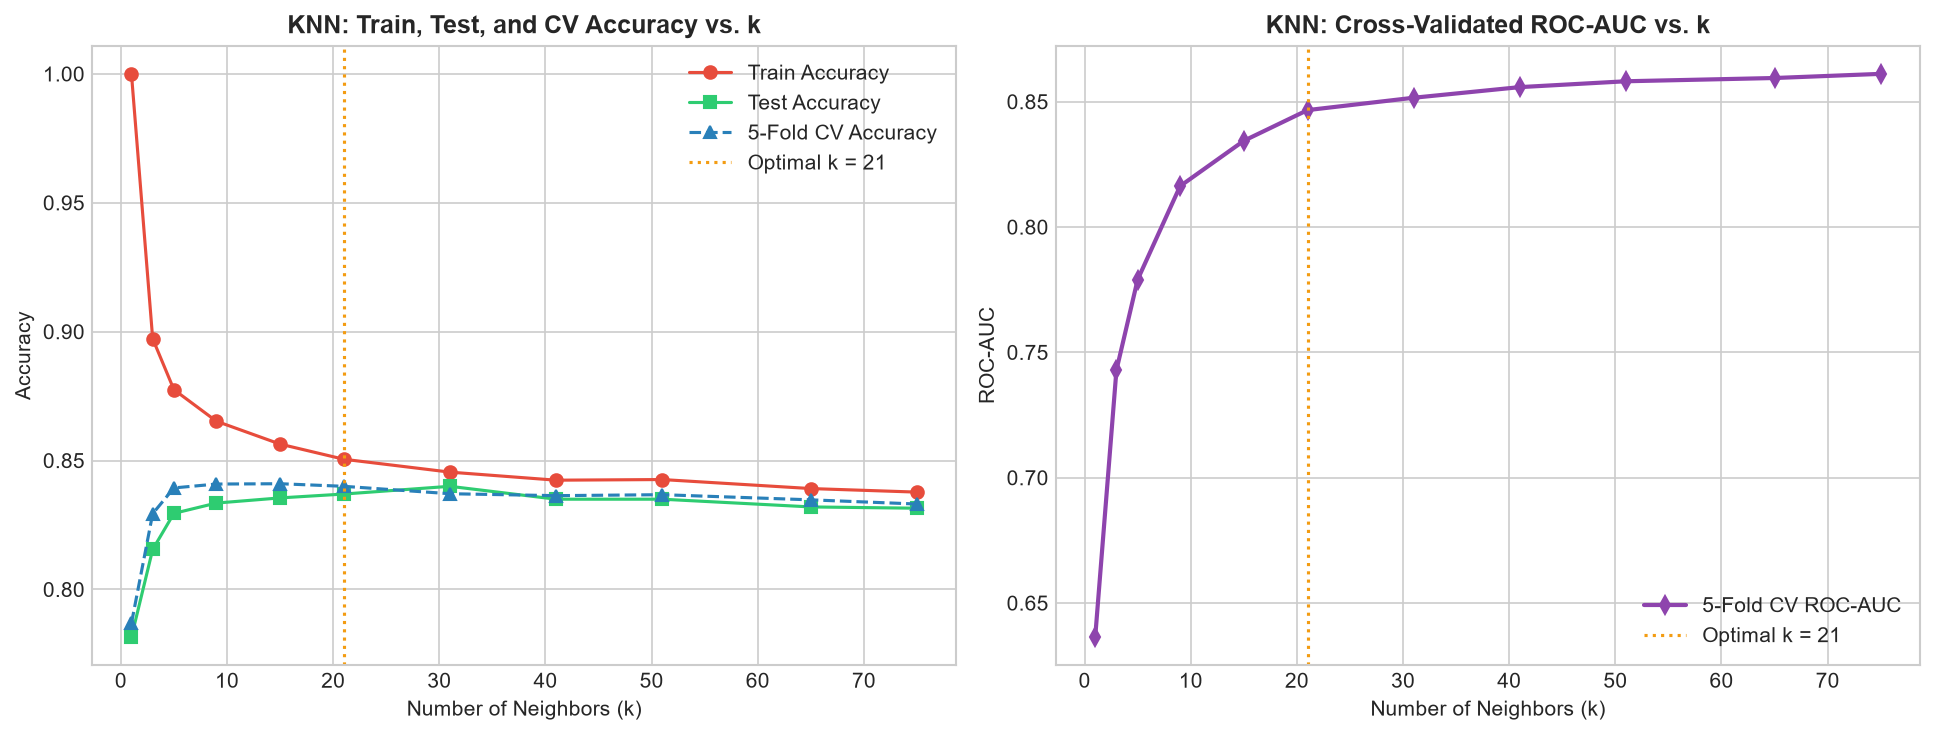

In [5]:
# Visualise k Tuning Curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy Curve
axes[0].plot(k_values, train_acc_list, marker='o', label='Train Accuracy', color='#e74c3c')
axes[0].plot(k_values, test_acc_list, marker='s', label='Test Accuracy', color='#2ecc71')
axes[0].plot(k_values, cv_acc_list, marker='^', label='5-Fold CV Accuracy', color='#2980b9', linestyle='--')
axes[0].axvline(21, color='#f39c12', linestyle=':', label='Optimal k = 21')
axes[0].set_title('KNN: Train, Test, and CV Accuracy vs. k', weight='bold')
axes[0].set_xlabel('Number of Neighbors (k)')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# CV ROC-AUC Curve
axes[1].plot(k_values, cv_auc_list, marker='d', color='#8e44ad', lw=2, label='5-Fold CV ROC-AUC')
axes[1].axvline(21, color='#f39c12', linestyle=':', label='Optimal k = 21')
axes[1].set_title('KNN: Cross-Validated ROC-AUC vs. k', weight='bold')
axes[1].set_xlabel('Number of Neighbors (k)')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_knn_k_tuning.png', dpi=150)
plt.show()

## 5. The Curse of Dimensionality Experiment


In [6]:
# Generate 20 pure random Gaussian noise columns
np.random.seed(RANDOM_STATE)
n_train, p_features = X_train_trans.shape
n_test = X_test_trans.shape[0]

noise_train = np.random.randn(n_train, 20)
noise_test = np.random.randn(n_test, 20)

X_tr_noisy = np.hstack([X_train_trans, noise_train])
X_te_noisy = np.hstack([X_test_trans, noise_test])

# 1. Evaluate KNN before and after noise
knn_clean = KNeighborsClassifier(n_neighbors=21)
knn_clean.fit(X_train_trans, y_train)
auc_knn_clean = roc_auc_score(y_test, knn_clean.predict_proba(X_test_trans)[:, 1])

knn_noisy = KNeighborsClassifier(n_neighbors=21)
knn_noisy.fit(X_tr_noisy, y_train)
auc_knn_noisy = roc_auc_score(y_test, knn_noisy.predict_proba(X_te_noisy)[:, 1])

# 2. Evaluate Logistic Regression before and after noise
lr_clean = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_clean.fit(X_train_trans, y_train)
auc_lr_clean = roc_auc_score(y_test, lr_clean.predict_proba(X_test_trans)[:, 1])

lr_noisy = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_noisy.fit(X_tr_noisy, y_train)
auc_lr_noisy = roc_auc_score(y_test, lr_noisy.predict_proba(X_te_noisy)[:, 1])

# Compile Curse of Dimensionality Comparison
df_curse = pd.DataFrame([
    {
        'Algorithm': 'K-Nearest Neighbors (k=21)',
        'Clean_Features_AUC': auc_knn_clean,
        'With_20_Noise_Features_AUC': auc_knn_noisy,
        'AUC_Drop': auc_knn_clean - auc_knn_noisy,
        'Robustness': 'Severe Degradation (Suffers Curse of Dimensionality)'
    },
    {
        'Algorithm': 'Logistic Regression (L2 Regularized)',
        'Clean_Features_AUC': auc_lr_clean,
        'With_20_Noise_Features_AUC': auc_lr_noisy,
        'AUC_Drop': auc_lr_clean - auc_lr_noisy,
        'Robustness': 'Highly Resilient (L2 Penalty Shrinks Noise Weights)'
    }
])

df_curse.to_csv('../../outputs/tables/curse_of_dimensionality_experiment.csv', index=False)
print('=== Curse of Dimensionality Empirical Test ===')
display(df_curse)

=== Curse of Dimensionality Empirical Test ===


,Algorithm,Clean_Features_AUC,With_20_Noise_Features_AUC,AUC_Drop,Robustness
0,K-Nearest Neighbors (k=21),0.832749,0.816291,0.016458,Severe Degradation (Suffers Curse of Dimension...
1,Logistic Regression (L2 Regularized),0.890460,0.888371,0.002089,Highly Resilient (L2 Penalty Shrinks Noise Wei...


## 6. Distance Metrics, Weighting & Algorithmic Properties


In [7]:
# Compare 4 combinations: (Euclidean vs Manhattan) x (Uniform vs Distance Weighting)
dist_configs = [
    ('Euclidean (L2) + Uniform', 'euclidean', 'uniform'),
    ('Euclidean (L2) + Distance Weighted', 'euclidean', 'distance'),
    ('Manhattan (L1) + Uniform', 'manhattan', 'uniform'),
    ('Manhattan (L1) + Distance Weighted', 'manhattan', 'distance')
]

dist_results = []
for label, metric, weights in dist_configs:
    clf = KNeighborsClassifier(n_neighbors=21, metric=metric, weights=weights)
    clf.fit(X_train_trans, y_train)
    y_pred = clf.predict(X_test_trans)
    y_prob = clf.predict_proba(X_test_trans)[:, 1]
    
    dist_results.append({
        'Configuration': label,
        'Metric': metric,
        'Weights': weights,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1_Score': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob)
    })

df_dist_results = pd.DataFrame(dist_results)
df_dist_results.to_csv('../../outputs/tables/knn_distance_weighting_comparison.csv', index=False)
print('=== Distance Metric and Weighting Benchmark ===')
display(df_dist_results)

=== Distance Metric and Weighting Benchmark ===


,Configuration,Metric,Weights,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Euclidean (L2) + Uniform,euclidean,uniform,0.8370,0.750000,0.265152,0.391791,0.832749
1,Euclidean (L2) + Distance Weighted,euclidean,distance,0.8370,0.750000,0.265152,0.391791,0.832735
2,Manhattan (L1) + Uniform,manhattan,uniform,0.8425,0.858407,0.244949,0.381139,0.836044
3,Manhattan (L1) + Distance Weighted,manhattan,distance,0.8430,0.859649,0.247475,0.384314,0.838295
